# Tome S1, Chapter 6: Singular Values (Python companion)

Exercises first, solutions at the end. We compute an SVD the textbook way and see why nobody does, compress a picture and watch the Eckart–Young error formula hold to the last digit, compare principal components with regression, superimpose two shapes with Procrustes, and complete a small Netflix-style ratings matrix. We use `numpy`, `matplotlib` and the standard library.

*Before each solution, predict what the output will look like.*

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(6)

## Exercises

**P6.1 (★) The textbook SVD.** Compute the singular values of a matrix through the eigenvalues of $A^{\mathsf T}A$, exactly as in the proof of Theorem 6.1, and compare with `numpy.linalg.svd` for a $50\times10$ matrix with singular values $1,10^{-1},\dots,10^{-9}$. Which small singular values does the textbook method lose, and why (Exercise 6.11)?

**P6.2 (★★) Compressing a picture.** Build a $256\times256$ grey-scale picture (shapes, a gradient, some texture), plot its singular values on a log scale, show the approximations of rank $1,5,20,60$, and check that the Frobenius and operator errors are exactly $\bigl(\sum_{i>k}\sigma_i^2\bigr)^{1/2}$ and $\sigma_{k+1}$ (Theorem 6.5). How many numbers does each approximation need?

**P6.3 (★★) Nobody beats Eckart–Young.** For a random $30\times20$ matrix and $k=3$, try to find a better rank-$3$ approximation: random rank-$3$ matrices, then alternating least squares ($A\approx XY^{\mathsf T}$, solve for $X$ with $Y$ fixed, then for $Y$). What does alternating least squares converge to?

**P6.4 (★) PCA versus regression.** Plot the five points of Exercise 6.6 with the principal direction (slope $1/\varphi$) and the regression line (slope $0.6$). Then generate $300$ noisy points near a plane in $\R^3$ and recover the plane with Theorem 6.8: what fraction of the variance do two components explain?

**P6.5 (★) The pseudo-inverse.** For a rank-deficient $6\times5$ matrix $A$ and a vector $b$, compare `numpy.linalg.pinv(A) @ b`, the formula of Definition 6.6, and `numpy.linalg.lstsq`. Add a vector of $\ker A$ to the solution: the residual does not change, the norm does (Theorem 6.7). Check Penrose's four equations (Exercise 6.4).

**P6.6 (★★) Procrustes.** Take a star-shaped polygon, rotate it by an unknown angle, add noise, and recover the rotation with Theorem 6.10. Plot before and after. Then find the orthogonal matrix closest to a random $3\times3$ matrix and compare with its polar factor (Theorem 6.3, Exercise 6.7).

**P6.7 (★★★) A miniature Netflix Prize.** Simulate $200$ users and $100$ films whose ratings come from $3$ hidden tastes ($R=UV^{\mathsf T}$ plus noise), and observe a random $20\%$ of the entries. Fit a rank-$3$ model by regularised alternating least squares on the observed entries only, and measure the error on the hidden entries. Compare with predicting each film's average rating.

## Solutions

### P6.1
**How to find it.** Build $A=U\Sigma V^{\mathsf T}$ with random orthonormal $U,V$. The eigenvalues of $A^{\mathsf T}A$ are $\sigma_i^2$, down to $10^{-18}$, below the rounding error $\approx10^{-16}\sigma_1^2$ of the computed $A^{\mathsf T}A$.

In [2]:
m, n = 50, 10
U, _ = np.linalg.qr(rng.standard_normal((m, n))); V, _ = np.linalg.qr(rng.standard_normal((n, n)))
sig = 10.0 ** -np.arange(n)
A = U @ np.diag(sig) @ V.T
textbook = np.sqrt(np.abs(np.sort(np.linalg.eigvalsh(A.T @ A))[::-1]))
library = np.linalg.svd(A, compute_uv=False)
print(" true        textbook      numpy.svd")
for t, a, b in zip(sig, textbook, library):
    print(f"{t:8.0e}   {a:11.3e}   {b:11.3e}")

 true        textbook      numpy.svd
   1e+00     1.000e+00     1.000e+00
   1e-01     1.000e-01     1.000e-01
   1e-02     1.000e-02     1.000e-02
   1e-03     1.000e-03     1.000e-03
   1e-04     1.000e-04     1.000e-04
   1e-05     1.000e-05     1.000e-05
   1e-06     9.999e-07     1.000e-06
   1e-07     9.966e-08     1.000e-07
   1e-08     9.716e-09     1.000e-08
   1e-09     1.374e-09     1.000e-09


The textbook method is accurate down to about $10^{-6}$, degrades around $10^{-7}$ and $10^{-8}$ (near the square root of machine precision, $10^{-8}$) and returns noise below; Golub–Kahan's algorithm works on $A$ itself and keeps all ten values.

### P6.2
**How to find it.** Any picture with large smooth regions has rapidly decaying singular values; texture and sharp edges create the long tail. The cost of rank $k$ is $k(m+n+1)$ numbers.

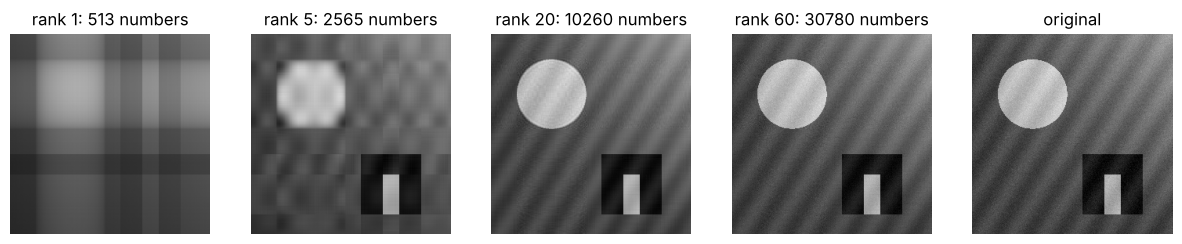

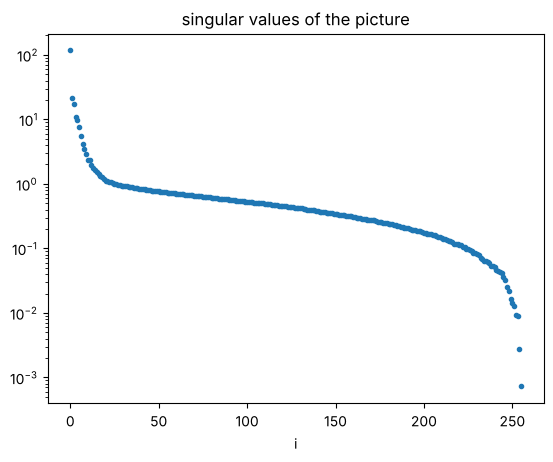

k= 1: ||E||_F = 34.567688  formula 34.567688   ||E|| = 21.543333  sigma_(k+1) = 21.543333
k= 5: ||E||_F = 14.621776  formula 14.621776   ||E|| = 7.553946  sigma_(k+1) = 7.553946
k=20: ||E||_F = 7.701446  formula 7.701446   ||E|| = 1.120296  sigma_(k+1) = 1.120296
k=60: ||E||_F = 5.389824  formula 5.389824   ||E|| = 0.709469  sigma_(k+1) = 0.709469


In [3]:
N = 256
yy, xx = np.mgrid[0:N, 0:N] / N
img = 0.3 + 0.4 * xx * (1 - yy)
img += 0.5 * (((xx - 0.3)**2 + (yy - 0.3)**2) < 0.03)
img[(yy > 0.6) & (yy < 0.9) & (xx > 0.55) & (xx < 0.85)] = 0.1
img[(yy > 0.7) & (yy < 0.9) & (xx > 0.66) & (xx < 0.74)] = 0.8           # a door
img += 0.06 * np.sin(40 * xx + 25 * yy)                                  # texture
img += 0.03 * rng.standard_normal((N, N))
U, s, Vt = np.linalg.svd(img)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, k in zip(axes, [1, 5, 20, 60, None]):
    M = img if k is None else (U[:, :k] * s[:k]) @ Vt[:k]
    ax.imshow(M, cmap='gray', vmin=0, vmax=1.2); ax.axis('off')
    ax.set_title("original" if k is None else f"rank {k}: {k * (2 * N + 1)} numbers")
plt.show()
plt.semilogy(s, '.'); plt.title("singular values of the picture"); plt.xlabel("i"); plt.show()
for k in (1, 5, 20, 60):
    E = img - (U[:, :k] * s[:k]) @ Vt[:k]
    print(f"k={k:2d}: ||E||_F = {np.linalg.norm(E):.6f}  formula {math.sqrt(np.sum(s[k:]**2)):.6f}   "
          f"||E|| = {np.linalg.norm(E, 2):.6f}  sigma_(k+1) = {s[k]:.6f}")

### P6.3
**How to find it.** Alternating least squares: with $Y$ fixed, the best $X$ solves a least squares problem for each row, $X=AY(Y^{\mathsf T}Y)^{-1}$; similarly for $Y$. Each step decreases the error, and the error cannot go below the Eckart–Young bound.

Eckart-Young optimum 18.990502, best of 2000 random tries 24.167, ALS after 60 steps 18.990502


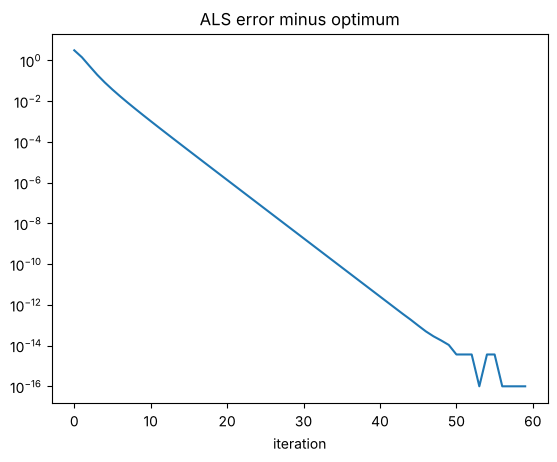

In [4]:
A = rng.standard_normal((30, 20)); k = 3
s = np.linalg.svd(A, compute_uv=False)
best = math.sqrt(np.sum(s[k:]**2))
rand_best = min(np.linalg.norm(A - rng.standard_normal((30, k)) @ rng.standard_normal((k, 20)) * t)
                for t in np.linspace(0.01, 1, 20) for _ in range(100))
X, Y = rng.standard_normal((30, k)), rng.standard_normal((20, k)); hist = []
for it in range(60):
    X = A @ Y @ np.linalg.inv(Y.T @ Y)
    Y = A.T @ X @ np.linalg.inv(X.T @ X)
    hist.append(np.linalg.norm(A - X @ Y.T))
print(f"Eckart-Young optimum {best:.6f}, best of 2000 random tries {rand_best:.3f}, ALS after 60 steps {hist[-1]:.6f}")
plt.semilogy(np.array(hist) - best + 1e-16); plt.title("ALS error minus optimum"); plt.xlabel("iteration"); plt.show()

Alternating least squares converges to the optimum $A_k$ (for generic starting points): its fixed points with full rank span singular subspaces, and only the top one is stable. This is the "power method" in disguise, and it is how low-rank models are fitted when entries are missing, as in P6.7.

### P6.4
**How to find it.** Centre the data, take the SVD of the data matrix, read the principal directions from $V$.

PCA slope 0.618034 (1/phi = 0.618034), regression slope 0.6


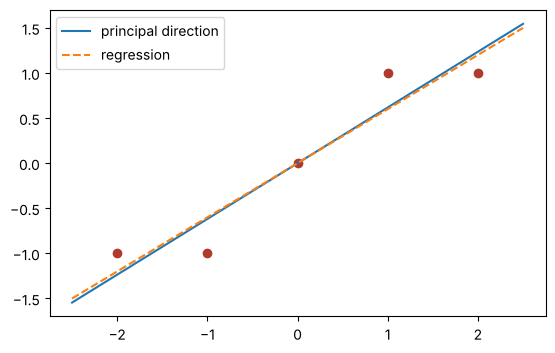

variance explained by 2 components: 0.99907
recovered normal: [-0.336 -0.669 -0.662]  true normal: [0.333 0.667 0.667] (up to sign)


In [5]:
P = np.array([[-2, -1], [-1, -1], [0, 0], [1, 1], [2, 1.]])
_, s2, Vt2 = np.linalg.svd(P)
slope_pca = Vt2[0, 1] / Vt2[0, 0]; slope_reg = (P[:, 0] @ P[:, 1]) / (P[:, 0] @ P[:, 0])
print(f"PCA slope {slope_pca:.6f} (1/phi = {(math.sqrt(5) - 1) / 2:.6f}), regression slope {slope_reg}")
x = np.linspace(-2.5, 2.5, 2)
plt.plot(P[:, 0], P[:, 1], 'o', color='#b03a2e')
plt.plot(x, slope_pca * x, label='principal direction'); plt.plot(x, slope_reg * x, '--', label='regression')
plt.gca().set_aspect('equal'); plt.legend(); plt.show()

normal = np.array([1, 2, 2]) / 3
B = np.linalg.svd(normal[None, :])[2][1:]                           # basis of the plane
pts = rng.standard_normal((300, 2)) @ np.diag([3, 1]) @ B + 0.1 * rng.standard_normal((300, 3))
pts -= pts.mean(axis=0)
_, s3, Vt3 = np.linalg.svd(pts)
print("variance explained by 2 components:", (np.sum(s3[:2]**2) / np.sum(s3**2)).round(5))
print("recovered normal:", Vt3[2].round(3), " true normal:", normal.round(3), "(up to sign)")

### P6.5
**How to find it.** A rank-deficient matrix: multiply a $6\times3$ by a $3\times5$. The kernel is spanned by the last right singular vectors.

In [6]:
A = rng.standard_normal((6, 3)) @ rng.standard_normal((3, 5)); b = rng.standard_normal(6)
U, s, Vt = np.linalg.svd(A); r = int(np.sum(s > 1e-10 * s[0]))
Aplus = sum(np.outer(Vt[i], U[:, i]) / s[i] for i in range(r))
x1, x2, x3 = np.linalg.pinv(A) @ b, Aplus @ b, np.linalg.lstsq(A, b, rcond=None)[0]
print("rank", r, "  three solutions agree:", np.allclose(x1, x2) and np.allclose(x1, x3))
z = Vt[r]                                                            # in ker A
for t in (0, 1, 3):
    x = x1 + t * z
    print(f"x + {t} z: residual {np.linalg.norm(A @ x - b):.6f}, norm {np.linalg.norm(x):.6f}")
X = Aplus
print("Penrose:", np.allclose(A @ X @ A, A), np.allclose(X @ A @ X, X), np.allclose((A @ X).T, A @ X), np.allclose((X @ A).T, X @ A))

rank 3   three solutions agree: True
x + 0 z: residual 0.830083, norm 1.066646
x + 1 z: residual 0.830083, norm 1.462099
x + 3 z: residual 0.830083, norm 3.183981
Penrose: True True True True


### P6.6
**How to find it.** With the points as columns of $A$ (original) and $B$ (observed), the optimal $Q$ is $UV^{\mathsf T}$ from the SVD of $BA^{\mathsf T}$.

recovered angle: 1.1045  true: 1.1


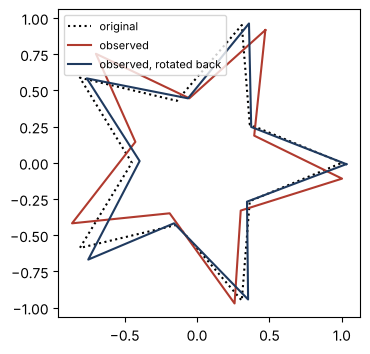

polar factor distance: 0.940704  formula: 0.940704  best of 20000 random orthogonal: 1.188278


In [7]:
t = np.linspace(0, 2 * np.pi, 11)[:-1]
star = np.vstack([np.cos(t), np.sin(t)]) * np.where(np.arange(10) % 2 == 0, 1.0, 0.45)
theta = 1.1
Rot = np.array([[math.cos(theta), -math.sin(theta)], [math.sin(theta), math.cos(theta)]])
obs = Rot @ star + 0.05 * rng.standard_normal(star.shape)
Uq, _, Vqt = np.linalg.svd(obs @ star.T)
Q = Uq @ Vqt
print("recovered angle:", round(math.atan2(Q[1, 0], Q[0, 0]), 4), " true:", theta)
fig, ax = plt.subplots(figsize=(4, 4))
cl = lambda M: np.hstack([M, M[:, :1]])
ax.plot(*cl(star), 'k:', label='original'); ax.plot(*cl(obs), color='#b03a2e', label='observed')
ax.plot(*cl(Q.T @ obs), color='#1f3a5f', label='observed, rotated back'); ax.set_aspect('equal'); ax.legend(fontsize=8)
plt.show()

M = rng.standard_normal((3, 3))
U3, s3, V3t = np.linalg.svd(M); W = U3 @ V3t
cands = [np.linalg.qr(rng.standard_normal((3, 3)))[0] for _ in range(20000)]
print("polar factor distance:", round(float(np.linalg.norm(M - W)), 6), " formula:", round(math.sqrt(np.sum((s3 - 1)**2)), 6),
      " best of 20000 random orthogonal:", round(float(min(np.linalg.norm(M - Q) for Q in cands)), 6))

### P6.7
**How to find it.** Alternating least squares as in P6.3, but each user's taste vector is fitted only on the films that user rated, and vice versa, with a small ridge penalty $\mu\|x\|^2$ to avoid overfitting users with few ratings.

In [8]:
nu, nf, k = 200, 100, 3
Utrue, Vtrue = rng.standard_normal((nu, k)), rng.standard_normal((nf, k))
Rfull = 3 + Utrue @ Vtrue.T / math.sqrt(k) + 0.3 * rng.standard_normal((nu, nf))
mask = rng.random((nu, nf)) < 0.2
mu = Rfull[mask].mean()
X, Y, lam = 0.1 * rng.standard_normal((nu, k)), 0.1 * rng.standard_normal((nf, k)), 1.0
for it in range(30):
    for i in range(nu):
        J = mask[i]; Yi = Y[J]
        X[i] = np.linalg.solve(Yi.T @ Yi + lam * np.eye(k), Yi.T @ (Rfull[i, J] - mu))
    for j in range(nf):
        I = mask[:, j]; Xj = X[I]
        Y[j] = np.linalg.solve(Xj.T @ Xj + lam * np.eye(k), Xj.T @ (Rfull[I, j] - mu))
pred = mu + X @ Y.T
film_avg = np.array([Rfull[mask[:, j], j].mean() for j in range(nf)])
rmse = lambda P: math.sqrt(np.mean((P - Rfull)[~mask]**2))
print(f"hidden-entry RMSE: rank-3 model {rmse(pred):.3f}, film averages {rmse(np.tile(film_avg, (nu, 1))):.3f}, "
      f"noise level 0.300")

hidden-entry RMSE: rank-3 model 0.347, film averages 1.068, noise level 0.300


With a fifth of the entries, the low-rank model predicts the hidden ratings almost to the noise level, while film averages, blind to individual tastes, do much worse. The real Netflix matrix had about $1\%$ of its entries observed and many more hidden tastes, but the principle is the same.